# Human annotation in the study: an overview

**Study:** Implication-Weighted Data Selection for Financial QA (Protocol v1) and the AAAI workshop paper (`specs/Protocol_for_AAAI_workshop.md`, Experiment 8).

This notebook gathers in one place everything the study asks of human annotators:

- **which annotation tasks exist**, why each is needed and what it decides;
- **the CBI hand audit**, the one task completed so far: its design, the annotation process, annotator agreement, the adjudication of disagreements, and the final labels;
- **what is still open**: the validation of the Q3 consequence checks.

The audit's results are interpreted in context elsewhere: notebook 03, §11 (what the confident errors are) and notebook 03b, §6b (what the audit says about the judges' verdicts). This notebook documents the annotation study itself.

**Purely descriptive.** It reads only frozen snapshots, each verified against its `SHA256SUMS`:

- `code/runs/cbi_audit_2026-10-31/` (the returned sheets of all three annotators, the instructions, the sample design, the imported labels and the final per-item labels);
- `code/runs/full_v2_2026-10-25/` (the pool, for each item's dataset and answer type, and the Q3 checks).

It imports nothing from the pipeline, calls no API, and changes no code, configuration or output. Its only outputs are this notebook and `notebooks/figures/annotation_cbi_audit.pdf`.

## 1. Setup and integrity

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact
from sklearn.metrics import cohen_kappa_score
from statsmodels.stats.proportion import proportion_confint

CODE = Path.cwd().parent / "code"
AUD_DIR = CODE / "runs" / "cbi_audit_2026-10-31"
V2_DIR = CODE / "runs" / "full_v2_2026-10-25"
AUD = AUD_DIR / "annotation" / "cbi_audit"
FIG_DIR = Path.cwd() / "figures"
FIG_DIR.mkdir(exist_ok=True)
N_BOOT = 2000
pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

LABELS = ["model_error", "scoring_artefact", "ambiguous_question", "questionable_gold"]
NAME = {"model_error": "model error", "scoring_artefact": "scoring artefact",
        "ambiguous_question": "ambiguous question", "questionable_gold": "questionable gold"}
ITEM_PROBLEM = {"ambiguous_question", "questionable_gold"}
ANNOTATORS = ["annotator_1", "annotator_2"]


def verify(folder):
    for line in (folder / "SHA256SUMS").read_text().splitlines():
        digest, rel = line.split(maxsplit=1)
        if hashlib.sha256((folder / rel).read_bytes()).hexdigest() != digest:
            return False
    return True

for d in (AUD_DIR, V2_DIR):
    print(f"{d.name:24s} checksums verified: {verify(d)}")

cbi_audit_2026-10-31     checksums verified: True
full_v2_2026-10-25       checksums verified: True


## 2. The annotation tasks

| Task | Why it is needed | Size | Who | Status |
| --- | --- | --- | --- | --- |
| **Q3 check validation** (Spec 1) | Jev's consequence question Q3, and therefore I, rests on automatically generated consequence checks. The generator is accepted only if both annotators judge ≥ 90% of a sample to "follow from the answer"; otherwise the checks are regenerated and Q3 re-scored. | 100 LLM-generated checks, stratified by dataset | 2 annotators, every item | **Open.** Pilot sheets exported 24 Oct (86 LLM checks and 120 template checks per annotator), never labelled. They must be re-exported from the full pool. |
| **Q3 template checks** (Spec 1) | Template checks are validated on hand-checked items. | 50 items per template | 2 annotators | **Open**, with the above. |
| **CBI hand audit** (workshop protocol, Experiment 8) | Of Qwen's confident errors (the same wrong answer in 5 of 5 samples), how many are model errors, and how many are scoring artefacts or item problems (an ambiguous question or a questionable gold label)? The CBI paper's recommended "Q4 mass on a small labelled sample". | 60 items in two strata of 30 | 2 annotators (20 items both), 1 adjudicator | **Done** (30 Oct): §3–§8 |

Every task uses the same CSV workflow (`fqsel.annotate`):
- each annotator gets a sheet with opaque row IDs (item IDs can reveal validation status), in their own random order;
- they fill only the label column and an optional note;
- the import refuses a returned sheet with added, removed, reordered or edited rows (each row carries a hash of its item columns) or a label outside the task's set;
- an export never overwrites a sheet with labels in it.

## 3. CBI hand audit: design

**Population:** the 281 CBI items of notebook 03 (§9–10): among the 1,730 items Qwen3-235B answered unanimously (1 − H/log n ≥ 0.8 over 5 samples), those where fewer than 3 of 5 samples match the gold under exact match plus numeric equivalence.

**Strata** (design recorded 26 Oct 2026 before any label existed; owner decision, "defensible minimum"):
- **A:** 30 of the 90 items where Jev rejects the gold and supports Qwen's answer (P(yes) < 0.5 on the gold, ≥ 0.5 on Qwen's);
- **B:** 30 of the other 191 items, allocated in proportion to Jev's three other verdict cells.

A third of each stratum (10 + 10) went on both sheets, for agreement; the other 40 were split evenly. Each annotator therefore labelled 40 items.

**What annotators saw:** the item (context, table and question), the gold answer with the calculation that produced it, and Qwen's answer with its reasoning. They never saw the stratum, Jev's scores or the item ID.

In [2]:
design = pd.read_csv(AUD / "_design.csv").set_index("item_id")
pool = pd.read_parquet(V2_DIR / "data" / "pool.parquet").set_index("item_id")
design = design.join(pool[["dataset", "answer_type"]])
print("Items by stratum and Jev's verdict cell, single- or double-annotated:")
display(pd.crosstab([design["stratum"], design["cell"]], design["double"].map({True: "both annotators", False: "one annotator"}),
                    margins=True, margins_name="total"))
load = {a: int(design["annotators"].str.split(";").apply(lambda xs, a=a: a in xs).sum()) for a in ANNOTATORS}
print("Items per annotator:", load)
print("Items by dataset and answer type:")
display(pd.crosstab([design["dataset"], design["answer_type"]], design["stratum"], margins=True, margins_name="total"))

Items by stratum and Jev's verdict cell, single- or double-annotated:


double                        both annotators  one annotator  total
stratum cell                                                       
A       jev_sides_with_model               10             20     30
B       both_supported                      8             18     26
        gold_only                           1              1      2
        neither                             1              1      2
total                                      20             40     60

Items per annotator: {'annotator_1': 40, 'annotator_2': 40}
Items by dataset and answer type:


stratum               A   B  total
dataset answer_type               
finqa   arith        26  10     36
tatqa   arith         3   4      7
        lookup        1  16     17
total                30  30     60

**The instructions annotators received** (verbatim, from the snapshot):

In [3]:
from IPython.display import Markdown
display(Markdown((AUD / "INSTRUCTIONS.md").read_text()))

# CBI hand audit: instructions for annotators

Each row is a financial question that a strong language model answered **the same way in five out of five
attempts**, with an answer that does **not** match the dataset's gold answer. Your task is to decide **why**
the model's answer counts as wrong. You see the context (text and table), the question, the gold answer
with the calculation that produced it, and the model's answer with its reasoning.

Put exactly one of these labels in the `category` column:

| Label | Use it when |
| --- | --- |
| `model_error` | The question is clear, the gold answer is right, and the model's answer is wrong. |
| `scoring_artefact` | The model's answer is actually correct, just written differently (format, units, rounding, wording). |
| `ambiguous_question` | The question can reasonably be read in more than one way, and the model's answer is right under a defensible reading. |
| `questionable_gold` | The gold answer or its calculation looks wrong given the context and the question. |

If two labels seem to apply, choose the one that best explains the disagreement, and explain in `note`.
Use `note` for anything else that matters (for example, which reading of the question each answer uses).

Do not edit, add, delete or reorder rows, and do not change any column other than `category` and `note`.
Return the file under the same name.


## 4. The annotation process

- **26 Oct:** sheets exported (`python -m fqsel annotate export cbi_audit`), with `INSTRUCTIONS.md`.
- **30 Oct:** both sheets returned complete (40 rows each, every label valid, no item edited) and imported (`annotate import cbi_audit`).
- **30 Oct:** the 6 double-annotated items with different labels went on one sheet for a third annotator (`annotate adjudicate cbi_audit`), showing both earlier labels and notes next to the item; returned the same day and imported (`annotate import-adjudication cbi_audit`), which checks that only the label and note columns changed.

The import verifies the returned sheets against what was sent; the checks are repeated here on the archived copies.

In [4]:
for a in ANNOTATORS:
    sent = pd.read_csv(AUD / f"{a}.csv", dtype=str, keep_default_na=False)
    back = pd.read_csv(AUD / "returned" / f"{a}.csv", dtype=str, keep_default_na=False)
    print(f"{a}: {len(back)} rows; rows unchanged in order: {list(back['row_id']) == list(sent['row_id'])}; "
          f"item hashes unchanged: {(back['row_hash'] == sent['row_hash']).all()}; "
          f"labels filled: {int(back['category'].str.strip().ne('').sum())}; notes: {int(back['note'].str.strip().ne('').sum())}")
adj = pd.read_csv(AUD / "adjudication" / "returned" / "annotator_3.csv", dtype=str, keep_default_na=False)
print(f"annotator_3 (adjudication): {len(adj)} rows; labels filled: {int(adj['category'].str.strip().ne('').sum())}; "
      f"notes: {int(adj['note'].str.strip().ne('').sum())}")
raw = pd.read_parquet(AUD / "labels.parquet")
final = pd.read_parquet(AUD / "final_labels.parquet").set_index("item_id").join(pool[["dataset", "answer_type"]])
print(f"imported labels: {len(raw)} (60 items, 20 of them twice); final labels: {len(final)} items")

annotator_1: 40 rows; rows unchanged in order: True; item hashes unchanged: True; labels filled: 40; notes: 0
annotator_2: 40 rows; rows unchanged in order: True; item hashes unchanged: True; labels filled: 40; notes: 5
annotator_3 (adjudication): 6 rows; labels filled: 6; notes: 0
imported labels: 80 (60 items, 20 of them twice); final labels: 60 items


## 5. What each annotator labelled

In [5]:
own = raw.join(design["stratum"], on="item_id")
tab = pd.crosstab([own["annotator"], own["stratum"]], own["label"]).reindex(columns=LABELS, fill_value=0)
tab["items"] = tab.sum(axis=1)
display(tab.rename(columns=NAME))

label                model error  scoring artefact  ambiguous question  \
annotator   stratum                                                      
annotator_1 A                  5                 2                   4   
            B                  4                12                   2   
annotator_2 A                  5                 0                   2   
            B                  4                13                   0   

label                questionable gold  items  
annotator   stratum                            
annotator_1 A                        9     20  
            B                        2     20  
annotator_2 A                       13     20  
            B                        3     20

Both annotators used all four labels, with similar profiles: about a quarter *model error*, and in stratum A mostly *questionable gold*, in stratum B mostly *scoring artefact*. Annotator 1 used *ambiguous question* more often (6 against 2) and *questionable gold* less (11 against 16).

## 6. Agreement between the two annotators

In [6]:
w = raw.pivot_table(index="item_id", columns="annotator", values="label", aggfunc="first").dropna()[ANNOTATORS]
w = w.join(design["stratum"])
merge = lambda s: s.where(~s.isin(ITEM_PROBLEM), "item_problem")
rng = np.random.default_rng(20261031)
boot = [rng.integers(0, len(w), len(w)) for _ in range(N_BOOT)]


def kappa_ci(a, b):
    a, b = np.asarray(a), np.asarray(b)
    reps = [cohen_kappa_score(a[i], b[i]) for i in boot if len(set(a[i]) | set(b[i])) > 1]
    lo, hi = np.nanpercentile(reps, [2.5, 97.5])
    return f"{cohen_kappa_score(a, b):.2f} [{lo:.2f}, {hi:.2f}]"

rows = {}
for name, f in (("four labels", lambda s: s), ("item-problem labels merged (three classes)", merge)):
    a, b = f(w["annotator_1"]), f(w["annotator_2"])
    rows[name] = {"items": len(w), "agree": int((a == b).sum()), "agreement": f"{(a == b).mean():.0%}",
                  "Cohen's κ (bootstrap 95% CI)": kappa_ci(a, b)}
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).T)
print("Agreement by stratum (four labels):", {s: f"{int((g['annotator_1'] == g['annotator_2']).sum())}/{len(g)}" for s, g in w.groupby("stratum")})
print("\nConfusion matrix of the 20 double-annotated items (rows: annotator 1, columns: annotator 2):")
display(pd.crosstab(w["annotator_1"].map(NAME), w["annotator_2"].map(NAME)).reindex(
    index=[NAME[l] for l in LABELS], columns=[NAME[l] for l in LABELS], fill_value=0))

,items,agree,agreement,Cohen's κ (bootstrap 95% CI)
four labels,20,14,70%,"0.60 [0.33, 0.85]"
item-problem labels merged (three classes),20,17,85%,"0.77 [0.46, 1.00]"


Agreement by stratum (four labels): {'A': '7/10', 'B': '7/10'}

Confusion matrix of the 20 double-annotated items (rows: annotator 1, columns: annotator 2):


annotator_2,model error,scoring artefact,ambiguous question,questionable gold
annotator_1,,,,
model error,5,0,0,1
scoring artefact,0,5,0,0
ambiguous question,1,0,1,3
questionable gold,1,0,0,3


**Findings: agreement.**
- **Moderate on the four labels, substantial once the two item-problem labels are merged:** 14 of 20 (κ 0.60), against 17 of 20 (κ 0.77). The confusion matrix shows why: half of the disagreements are *ambiguous question* against *questionable gold*, two descriptions of an item that is at fault. The distinction between a model error, a scoring artefact and an item problem is applied consistently.
- **Scoring artefacts are the most clear-cut category:** both annotators gave all 5 of them that label.
- **The intervals are wide** (20 items), as expected for the defensible-minimum design.

## 7. Adjudication of the disagreements

In [7]:
key = pd.read_csv(AUD / "_key.csv", dtype=str).set_index("row_id")["item_id"]
adj = adj.assign(item_id=adj["row_id"].map(key)).set_index("item_id").join(design[["stratum"]])
adj["decision"] = np.select([adj["category"] == adj["annotator_1_label"], adj["category"] == adj["annotator_2_label"]],
                            ["annotator 1's label", "annotator 2's label"], "a third label")
show = adj[["stratum", "annotator_1_label", "annotator_2_label", "category", "decision"]].rename(columns={"category": "final label"})
display(show.sort_values("stratum"))
print(adj["decision"].value_counts().to_dict())

,stratum,annotator_1_label,annotator_2_label,final label,decision
item_id,,,,,
finqa:UNP/2016/page_21.pdf-1,A,ambiguous_question,questionable_gold,ambiguous_question,annotator 1's label
finqa:AON/2010/page_100.pdf-3,A,ambiguous_question,model_error,model_error,annotator 2's label
finqa:HOLX/2011/page_122.pdf-3,A,model_error,questionable_gold,model_error,annotator 1's label
tatqa:033544b5-4deb-44e1-9818-5f81088da78f,B,ambiguous_question,questionable_gold,ambiguous_question,annotator 1's label
tatqa:b53d9e9b-0eef-49da-bdd4-f34d18aa9eb4,B,ambiguous_question,questionable_gold,ambiguous_question,annotator 1's label
finqa:AMT/2006/page_31.pdf-2,B,questionable_gold,model_error,questionable_gold,annotator 1's label


{"annotator 1's label": 5, "annotator 2's label": 1}


The third annotator chose one of the two earlier labels every time: annotator 1's in 5 cases and annotator 2's in 1. All three *ambiguous question* vs *questionable gold* splits went to *ambiguous question*. Two of the three splits between *model error* and an item problem went to *model error*.

## 8. Final labels

In [8]:
print("Where each final label comes from:", final["source"].value_counts().to_dict())


def share(k, n):
    lo, hi = proportion_confint(k, n, method="wilson")
    return f"{k}/{n} = {k / n:.0%} [{lo:.0%}, {hi:.0%}]"

SEL = {**{NAME[l]: (lambda g, l=l: g.eq(l)) for l in LABELS}, "item problem (ambiguous + questionable gold)": lambda g: g.isin(ITEM_PROBLEM)}
N_POP = {"A": 90, "B": 191}                       # CBI items per stratum (notebook 03, §10)
est = {}
for lab, f in SEL.items():
    p_hat, var = 0.0, 0.0
    for s in "AB":
        g = final.loc[final["stratum"] == s, "label"]
        n, p, W = len(g), f(g).mean(), N_POP[s] / sum(N_POP.values())
        p_hat += W * p
        var += W ** 2 * p * (1 - p) / (n - 1) * (1 - n / N_POP[s])
    est[lab] = f"{p_hat:.0%} [{max(0.0, p_hat - 1.96 * var ** 0.5):.0%}, {min(1.0, p_hat + 1.96 * var ** 0.5):.0%}]"
res = pd.DataFrame({name: {lab: share(int(f(final.loc[final["stratum"] == s, "label"]).sum()), int((final["stratum"] == s).sum()))
                           for lab, f in SEL.items()}
                    for name, s in (("A: Jev sides with Qwen (30 of 90)", "A"), ("B: other CBI (30 of 191)", "B"))})
res["all 281 CBI items (weighted estimate)"] = pd.Series(est)
with pd.option_context("display.max_colwidth", None):
    display(res)
for lab in ("item problem (ambiguous + questionable gold)", "model error", "scoring artefact"):
    k = [int(SEL[lab](final.loc[final["stratum"] == s, "label"]).sum()) for s in "AB"]
    print(f"{lab}: A {k[0]}/30 vs B {k[1]}/30, Fisher exact p = {fisher_exact([[k[0], 30 - k[0]], [k[1], 30 - k[1]]]).pvalue:.2g}")

Where each final label comes from: {'single': 40, 'agreed': 14, 'adjudicated': 6}


,A: Jev sides with Qwen (30 of 90),B: other CBI (30 of 191),all 281 CBI items (weighted estimate)
model error,"7/30 = 23% [12%, 41%]","5/30 = 17% [7%, 34%]","19% [9%, 28%]"
scoring artefact,"2/30 = 7% [2%, 21%]","20/30 = 67% [49%, 81%]","47% [36%, 58%]"
ambiguous question,"4/30 = 13% [5%, 30%]","2/30 = 7% [2%, 21%]","9% [2%, 15%]"
questionable gold,"17/30 = 57% [39%, 73%]","3/30 = 10% [3%, 26%]","25% [17%, 33%]"
item problem (ambiguous + questionable gold),"21/30 = 70% [52%, 83%]","5/30 = 17% [7%, 34%]","34% [24%, 43%]"


item problem (ambiguous + questionable gold): A 21/30 vs B 5/30, Fisher exact p = 6.3e-05
model error: A 7/30 vs B 5/30, Fisher exact p = 0.75
scoring artefact: A 2/30 vs B 20/30, Fisher exact p = 1.9e-06


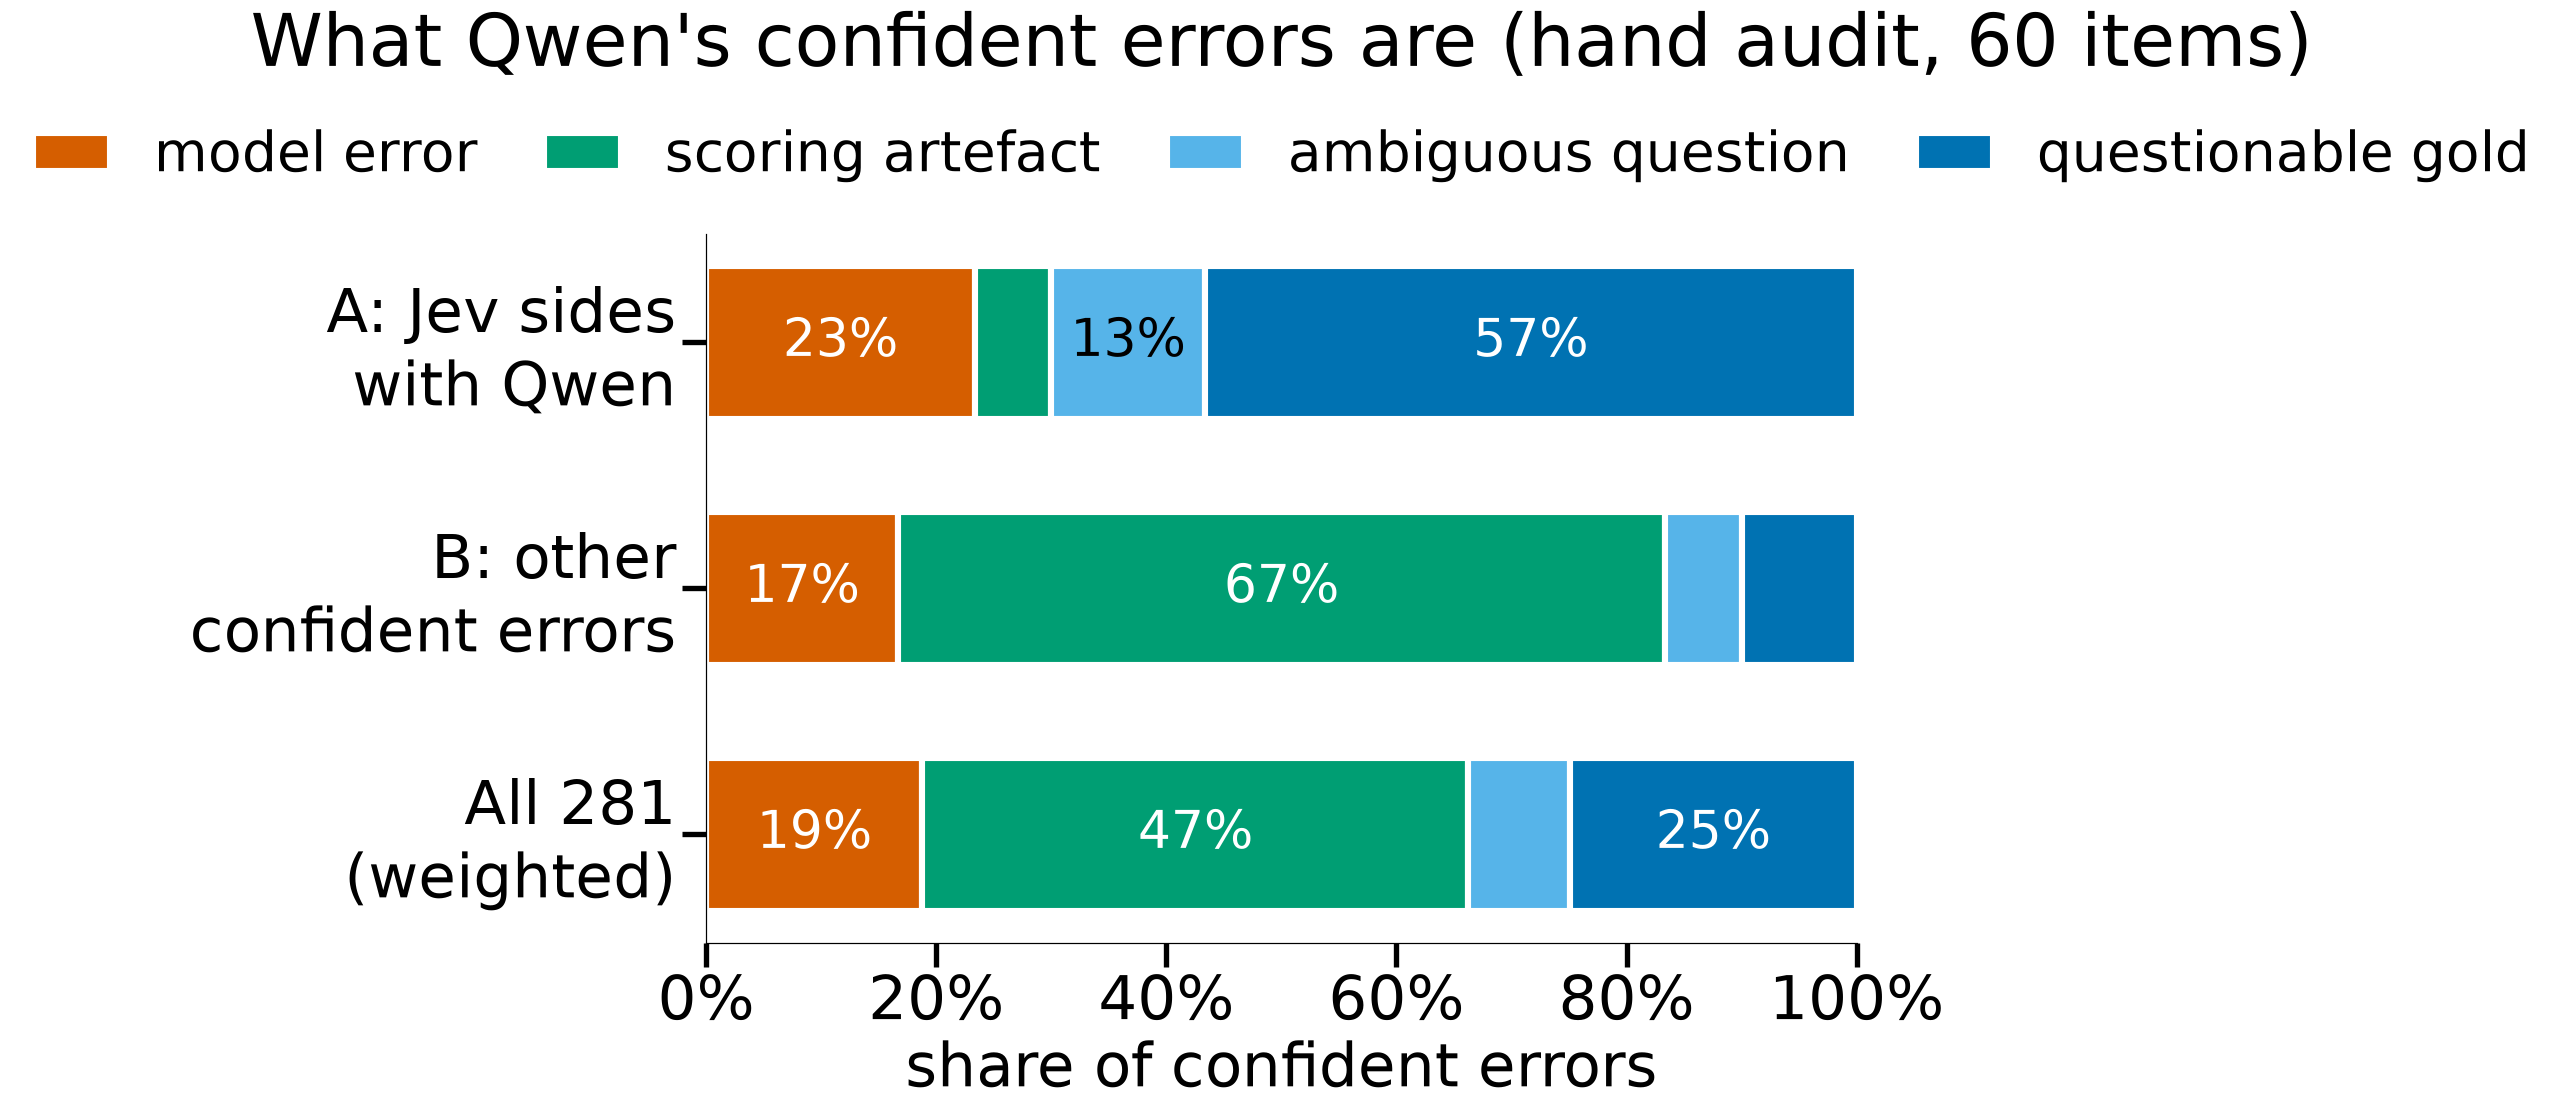

In [9]:
# Okabe-Ito colours (Wong, Nature Methods 2011), as in the other figures; the two item-problem labels share the blue
# family. Checked for colour-vision deficiency; sky blue is below 3:1 on white, so segments carry white gaps and labels.
COL = {"model_error": "#D55E00", "scoring_artefact": "#009E73", "ambiguous_question": "#56B4E9", "questionable_gold": "#0072B2"}
weighted = {l: sum(N_POP[s] / 281 * final.loc[final["stratum"] == s, "label"].eq(l).mean() for s in "AB") for l in LABELS}
bars = {"A: Jev sides\nwith Qwen": final.loc[final["stratum"] == "A", "label"].value_counts(normalize=True),
        "B: other\nconfident errors": final.loc[final["stratum"] == "B", "label"].value_counts(normalize=True),
        "All 281\n(weighted)": pd.Series(weighted)}
fig, ax = plt.subplots(figsize=(22, 10), layout="constrained")
for y, (name, shares) in enumerate(bars.items()):
    left = 0.0
    for l in LABELS:
        v = float(shares.get(l, 0.0))
        ax.barh(y, v, left=left, height=0.62, color=COL[l], edgecolor="white", linewidth=4, label=NAME[l] if y == 0 else None)
        if v >= 0.12:                              # narrower segments: values in the table above
            ax.text(left + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=34,
                    color="black" if l == "ambiguous_question" else "white")
        left += v
ax.set_yticks(range(len(bars)), list(bars), fontsize=40)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xticks(np.linspace(0, 1, 6), [f"{v:.0%}" for v in np.linspace(0, 1, 6)], fontsize=40)
ax.tick_params(length=16, width=3.5)
ax.set_xlabel("share of confident errors", fontsize=40)
ax.set_title("What Qwen's confident errors are (hand audit, 60 items)", fontsize=48, pad=110)
ax.legend(frameon=False, fontsize=36, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.0), columnspacing=1.2, handlelength=1.4)
fig.savefig(FIG_DIR / "annotation_cbi_audit.pdf", bbox_inches="tight")
plt.show()

In [10]:
print("Final labels by dataset and answer type:")
display(pd.crosstab([final["stratum"], final["dataset"], final["answer_type"]], final["label"]).reindex(columns=LABELS, fill_value=0)
        .rename(columns=NAME))

Final labels by dataset and answer type:


label                        model error  scoring artefact  \
stratum dataset answer_type                                  
A       finqa   arith                  6                 2   
        tatqa   arith                  1                 0   
                lookup                 0                 0   
B       finqa   arith                  2                 6   
        tatqa   arith                  1                 1   
                lookup                 2                13   

label                        ambiguous question  questionable gold  
stratum dataset answer_type                                         
A       finqa   arith                         4                 14  
        tatqa   arith                         0                  2  
                lookup                        0                  1  
B       finqa   arith                         0                  2  
        tatqa   arith                         1                  1  
                lookup                        1                  0

**Findings: what the confident errors are.**
- **About a fifth are model errors:** an estimated 19% [9, 28] of the 281, roughly 53 items or 3% of the unanimous answers, against the 16% automatic scoring reports.
- **Nearly half are scoring artefacts** (47% [36, 58]): Qwen's answer is right but written differently in a way that exact match plus numeric equivalence misses. Most are TAT-QA lookup spans.
- **A third are item problems** (34% [24, 43]): mostly questionable gold labels, mainly FinQA arithmetic.
- **The strata differ as designed:** where Jev sides with Qwen (A), 70% are item problems; elsewhere (B), 67% are scoring artefacts. Model errors are about a fifth in both (23% and 17%).

## 9. Annotators' notes

In [11]:
notes = pd.concat([raw.loc[raw["note"].notna(), ["item_id", "annotator", "label", "note"]],
                   adj.reset_index().loc[adj["note"].str.strip().ne("").to_numpy(), ["item_id"]].assign(annotator="annotator_3")])
notes = notes.join(design["stratum"], on="item_id").join(final["label"].rename("final label"), on="item_id")
with pd.option_context("display.max_colwidth", 200):
    display(notes.sort_values(["stratum", "item_id"]).reset_index(drop=True))

,item_id,annotator,label,note,stratum,final label
0,finqa:IP/2013/page_101.pdf-4,annotator_2,ambiguous_question,it can be either based on what the model assumes,A,ambiguous_question
1,finqa:JPM/2017/page_69.pdf-3,annotator_2,ambiguous_question,it can be either based on what the model assumes,A,ambiguous_question
2,finqa:AES/2001/page_86.pdf-2,annotator_2,model_error,"I think both are wrong, the answer should be 121",B,model_error
3,finqa:AMT/2006/page_31.pdf-2,annotator_2,model_error,"both are wrong, answer 9.11%",B,questionable_gold
4,tatqa:8f0787d3-81c8-45f2-814c-5aba06c7cb66,annotator_2,scoring_artefact,although the question asks about fraud and not funds,B,scoring_artefact


Only annotator 2 left notes (5 of 40 items); annotator 1 and the third annotator left none. Two notes say the question can be read either way, two that both the gold and Qwen's answer are wrong (giving the value the annotator computed), and one flags that Qwen's answer is about a different quantity than the question asks for. One of the "both are wrong" items was labelled *model error* by annotator 2 and *questionable gold* by annotator 1; the third annotator chose *questionable gold*.

## 10. Where the results are used

- **Notebook 03, §11:** the composition of the confident errors, by stratum and for all 281, and what it means for the CBI paper (Thread 2) and for the scoring decision (blocking question 5).
- **Notebook 03b, §6b:** for each of the four judges, what the items it sides with Qwen on turn out to be (65–70% item problems), and the 50 items three judges share (12 of 15 audited are item problems).
- **Workshop protocol, Experiment 8:** the results table and the paper-level findings.
- **Implementation plan:** the verification log rows of 31 Oct.

The labels are archived in `code/runs/cbi_audit_2026-10-31/` (DVC), and `code/tests/real_data/test_reproduction.py` re-imports the archived sheets and reproduces the final labels and both summaries.

In [12]:
checks = pd.read_parquet(V2_DIR / "data" / "q3_checks.parquet")
print("Q3 checks in the full pool by source (what the open validation task covers):")
display(checks.groupby("source").size().rename("checks").to_frame())

Q3 checks in the full pool by source (what the open validation task covers):


,checks
source,
llm,8200
template,12055


## 11. Still open: validating the Q3 checks

Everything built on Jev's Q3 (consequence) question, and therefore I, I′ and the selection conditions that use them, is provisional until the checks are validated (notebooks 00 §8, 01 §2 and §14, 02 §6.4 and §8, 04 §10). R does not depend on the checks.

**What is needed:**
1. **Re-export the sheets from the full pool** (`python -m fqsel annotate export q3_validation profile=full`, and `q3_templates`). The pilot sheets of 24 Oct were never labelled; the export will not overwrite a sheet that has labels in it.
2. **Two annotators** label each check *yes* or *no*: "does the check follow from the answer?" About 100 LLM-generated checks, stratified by dataset, plus 50 items per template.
3. **Decision rule (Spec 1):** if at least 90% of the LLM checks are labelled *yes* by both annotators, the generator is accepted; otherwise its prompt is revised, every LLM check regenerated and Q3 re-scored.

## 12. Limitations of the annotation study

1. **Small sample, by design.** 30 items per stratum gives intervals of about ±15 points per share; the "defensible minimum" was chosen to detect a large difference between strata (it found 70% against 17%), not to estimate rare categories.
2. **Two thirds of items have one annotator.** Agreement is measured on 20 items only, and single-annotated items carry each annotator's own tendencies (§5).
3. **One adjudicator** decided the 6 disagreements; their choices favoured annotator 1 (5 of 6).
4. **The categories need judgment.** *Ambiguous question* and *questionable gold* are hard to tell apart (half of the disagreements); merged, agreement is substantial. Analyses that need only "item problem" are on firmer ground than those that need the split.
5. **The sample was drawn by Jev's verdicts.** Shares for other groupings (other judges, all CBI) need the stratum weights used in §8 and in notebook 03b.
6. **Annotators saw Qwen's reasoning and the gold derivation.** That helps them find the source of a disagreement, but may anchor them on either side.